In [1]:
!pip uninstall -y torch torchvision torchaudio > /dev/null 2>&1
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118 > /dev/null 2>&1

In [2]:
!pip install sacremoses

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.5/897.5 kB 14.3 MB/s eta 0:00:00


In [3]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.9/183.9 kB 6.0 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.3.2
    Uninstalling fsspec-2025.3.2:
      Successfully uninstalled fsspec-2025.3.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2024.10.0 requires fsspec==2024.10.0, but you have fsspec 2024.12.0 which is incompatible.
bigframes 1.36.0 requires rich<14,>=12.4.4, but you have rich 14.0.0 which is incompatible.
fastai 2.7.18 requires torch<2.6,>=1.10, but you have torch 2.7.0+cu118 which is incompatible.


In [4]:
!pip install rouge_score
!pip install sacrebleu
!pip install bert-score

  Preparing metadata (setup.py) ... done
  Created wheel for rouge_score: filename=rouge_score-0.1.2-py3-none-any.whl size=24935 sha256=c01a7518b7692e16238e8a1ccac3ad9345f9ff901bd1d45608fc80043155f3ed
  Stored in directory: /root/.cache/pip/wheels/1e/19/43/8a442dc83660ca25e163e1bd1f89919284ab0d0c1475475148
Successfully built rouge_score
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.8/51.8 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.1/104.1 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.4 MB/s eta 0:00:00


In [5]:
import warnings
warnings.filterwarnings("ignore")

In [6]:
packages = [
    "langchain",
    "langchain_community",
    "langchain-huggingface",
    "sentence_transformers",
    "pypdf",
    "chromadb",
    "bitsandbytes",
    "transformers",
    "accelerate",
    "scikit-learn",
    "gradio",
    "typer==0.10.0"
]

for pkg in packages:
    print(f" Installing: {pkg}")
    !pip install -qU {pkg} > /dev/null 2>&1

print("All packages installed successfully.")

 Installing: langchain
 Installing: langchain_community
 Installing: langchain-huggingface
 Installing: sentence_transformers
 Installing: pypdf
 Installing: chromadb
 Installing: bitsandbytes
 Installing: transformers
 Installing: accelerate
 Installing: scikit-learn
 Installing: gradio
 Installing: typer==0.10.0
All packages installed successfully.


In [7]:
import torch

cuda_available = torch.cuda.is_available()
integrated_gpu_name = torch.cuda.get_device_name(0) if cuda_available else None

print("CUDA available:", cuda_available)
print("Integrated GPU name:", integrated_gpu_name)

CUDA available: True
Integrated GPU name: Tesla T4


In [8]:
import torch
import torchvision

print(torch.__version__)
print(torchvision.__version__)

2.7.0+cu118
0.22.0+cu118


In [9]:
import requests

url = "https://github.com/EchoSingh/FastMedicalBot/raw/main/Medical_Book.pdf"
response = requests.get(url)

with open("Medical_Book.pdf", "wb") as f:
    f.write(response.content)

In [10]:
from langchain.document_loaders import PyPDFLoader

loader = PyPDFLoader("Medical_Book.pdf")
documents = loader.load()

if len(documents) > 0:
    print("yes")
else:
    print("no")

from langchain.text_splitter import RecursiveCharacterTextSplitter
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=20)
all_splits = text_splitter.split_documents(documents)

print("Document text has been split into", len(all_splits), "chunks.")

yes
Document text has been split into 3006 chunks.


In [11]:
import gradio as gr
from transformers import AutoTokenizer, AutoModelForCausalLM
import tempfile

# Load the model and tokenizer
tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
model = AutoModelForCausalLM.from_pretrained("openai-community/gpt2")

# Text generation function with file export
def generate_text(prompt, max_length=100, temperature=0.7):
    inputs = tokenizer(prompt, return_tensors="pt")
    outputs = model.generate(
        **inputs,
        max_length=max_length,
        do_sample=True,
        temperature=temperature,
        top_k=50,
        top_p=0.95
    )
    text = tokenizer.decode(outputs[0], skip_special_tokens=True)

    # Save generated text to a temporary file
    with tempfile.NamedTemporaryFile(delete=False, suffix=".txt", mode="w") as f:
        f.write(text)
        filepath = f.name

    return text, filepath

# Create the Gradio interface
demo = gr.Interface(
    fn=generate_text,
    inputs=[
        gr.Textbox(label="Enter your prompt", lines=3, placeholder="Once upon a time..."),
        gr.Slider(50, 300, value=100, step=10, label="Max Length"),
        gr.Slider(0.1, 1.5, value=0.7, step=0.1, label="Temperature")
    ],
    outputs=[
        gr.Textbox(label="Generated Text"),
        gr.File(label="Download the result")
    ],
    title="🌟 GPT-2 Text Generator",
    description="✨ Enter a prompt to generate text with GPT-2. Adjust the settings and download your result!"
)

demo.launch()


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

2025-05-02 10:45:37.259145: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1746182737.677939      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1746182737.822687      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

* Running on local URL:  http://127.0.0.1:7860
It looks like you are running Gradio on a hosted a Jupyter notebook. For the Gradio app to work, sharing must be enabled. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

* Running on public URL: https://81941b147196947acf.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [12]:
import os
import sys

# Optionnel : masquer les messages d'avertissement
sys.stderr = open(os.devnull, 'w')

from langchain.vectorstores import Chroma
from langchain_huggingface import HuggingFaceEmbeddings

# Utilisation d'un modèle SentenceTransformers avec GPU
model_name = "microsoft/biogpt"
model_kwargs = {"device": "cuda"}  # <-- "cuda" pour le GPU (NVIDIA uniquement)

embeddings = HuggingFaceEmbeddings(model_name=model_name, model_kwargs=model_kwargs)

# Création d'une base vectorielle persistante avec Chroma
persist_directory = "chroma_db"
vectorstore = Chroma.from_documents(
    documents=all_splits,         # liste de documents (doit être définie avant)
    embedding=embeddings,
    persist_directory=persist_directory
)


config.json:   0%|          | 0.00/595 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.56G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.56G [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/927k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/696k [00:00<?, ?B/s]

In [13]:
from IPython.display import Markdown
def md(t):
  display(Markdown(t))

In [14]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, pipeline
from langchain.embeddings import HuggingFaceEmbeddings
from langchain.llms import HuggingFacePipeline

model_name = "ritvik77/Medical_Doctor_AI_LoRA-Mistral-7B-Instruct_FullModel"
device_map = 'auto'

# 4-bit quantization config
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
)

# Load model with quantization
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=bnb_config,
    trust_remote_code=True,
    use_cache=True,
    device_map=device_map
)

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
tokenizer.pad_token = tokenizer.eos_token

# Create generation pipeline
pipe = pipeline(
    "text-generation",
    model=model,
    tokenizer=tokenizer,
    max_new_tokens=150,
    temperature=0.7,
    top_p=0.9,
    do_sample=True
)

# Wrap with LangChain
llm = HuggingFacePipeline(pipeline=pipe)

config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/4.14G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/143k [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/587k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.67M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/787 [00:00<?, ?B/s]

In [15]:
from langchain.chains import ConversationalRetrievalChain
from langchain.prompts import PromptTemplate
from langchain.chains.question_answering import load_qa_chain
from langchain.chains.llm import LLMChain


condense_question_prompt = PromptTemplate(
    input_variables=["question", "chat_history"],
    template="""
You are a helpful medical assistant. Given the following conversation and a follow-up question, rephrase the follow-up question to be a standalone question.

Chat History:
{chat_history}

Follow-up Question:
{question}

Standalone Question:"""
)


qa_prompt = PromptTemplate(
    input_variables=["context", "question"],
    template="""
Use the following context to answer the question.

Context:
{context}

Question:
{question}

Answer:
"""
)



#  Chains 

question_generator = LLMChain(
    llm=llm,
    prompt=condense_question_prompt
)


combine_docs_chain = load_qa_chain(
    llm=llm,
    chain_type="stuff",
    prompt=qa_prompt
)


chain = ConversationalRetrievalChain(
    retriever=vectorstore.as_retriever(),
    combine_docs_chain=combine_docs_chain,
    question_generator=question_generator,
    return_source_documents=True
)

In [16]:
chat_history = []

question = "Patient reports chest pain and dizziness. What’s the likely diagnosis?"
result = chain({"question": question, "chat_history": chat_history})

# Update chat history
chat_history.append((question, result["answer"]))

print("Answer:", result["answer"])

Answer: 
Use the following context to answer the question.

Context:
ous heart conditions; gastrointestinal disorders of many
types, various gynecological conditions, sexual failures,
migraines and depressive states.”
Literature in the 1980s and 1990s went on to include
improvements in back pain, chronic pain, postural prob-
GALE ENCYCLOPEDIA OF MEDICINE 2 103
Alexander technique
GEM - 0001 to 0432 - A  10/22/03 1:41 PM  Page 103

reversible, can cause similar symptoms. It is important for
the person with these symptoms to be evaluated by a pro-
fessional who can weigh the possibility that his or her
symptoms may have another cause. Approximately 20% of
those originally suspected of having AD turn out to have
some other disorder; about half of these cases are treatable.
GALE ENCYCLOPEDIA OF MEDICINE 2136
Alzheimer’s disease
GEM - 0001 to 0432 - A  10/22/03 1:42 PM  Page 136

several factors. During a physical examination, the doc-
tor inquires about recent traumas or illnesses, drug an

In [17]:
query = "How to cure diabetes?"
result = chain.invoke({"question": query, "chat_history": chat_history})
md(result['answer'])


Use the following context to answer the question.

Context:
several factors. During a physical examination, the doc-
tor inquires about recent traumas or illnesses, drug and
medication history, and checks the patient’s general
health. Psychological exams may be ordered to deter-
mine the extent of amnesia and the memory system
affected. The doctor may also order imaging tests such as
magnetic resonance imaging(MRI) to reveal whether
the brain has been damaged, and blood work to exclude
treatable metabolic causes or chemical imbalances.
Treatment
Treatment depends on the root cause of amnesia and
is handled on an individual basis. Regardless of cause,
cognitive rehabilitation may be helpful in learning
strategies to cope with memory impairment.
GALE ENCYCLOPEDIA OF MEDICINE 2152
Amnesia
AmygdalaHippocampus
Memory loss may result from bilateral damage to the limbic
system of the brain responsible for memory storage, pro-
cessing, and recall.(Illustration by Electronic Illustrators Group).
GEM - 0001 to 0432 - A  10/22/03 1:42 PM  Page 152

reversible, can cause similar symptoms. It is important for
the person with these symptoms to be evaluated by a pro-
fessional who can weigh the possibility that his or her
symptoms may have another cause. Approximately 20% of
those originally suspected of having AD turn out to have
some other disorder; about half of these cases are treatable.
GALE ENCYCLOPEDIA OF MEDICINE 2136
Alzheimer’s disease
GEM - 0001 to 0432 - A  10/22/03 1:42 PM  Page 136

the brain has the potential to trigger seizures.
Normal results
After examining the brain tissue directly, no abnor-
malities are detected.
Abnormal results
Various brain abnormalities can be diagnosed by
microscopic analysis of the tissue sample. The pathologist
(a physician trained in how disease affects the body’s tis-
sues) looks for abnormal growth, changes in cell mem-
branes, and/or abnormal collections of cells. In Alzheimer’s
disease, the cortex of the brain contains abnormal collec-
tions of plaques. If infection is suspected, the infectious
organism can be cultured from the tissue and identified.
Classification of tumors is also possible after biopsy.
Resources
BOOKS
Zaret, B. L. The Yale University School of Medicine Patient’s
Guide to Medical Tests.Yale University School of Medi-
cine and G.S. Sharpe Communications Inc., 1997.
ORGANIZATIONS
Alzheimer’s Association. 919 North Michigan Avenue, Suite
1100 Chicago, IL 60611-1676.(800) 272-3900 <http://
www.alz.org/chapter/>.

Walther, a diplomate of the International College of
Applied Kinesiology, has indicated that “it is possible
that the central nervous system, recognizing the com-
pound being ingested, relays information to the organs
and glands preparing for use of the compound. If the
compound is recognized as beneficial, the energy pattern
is immediately enhanced, influencing not only the organ
or gland, but also the associated muscle.”
AK has been used as a diagnostic health tool for a
variety of conditions.
Bone health
• neck/low back pain and sciatica
• whiplash
• frozen shoulder
Joint health
• carpal tunnel syndrome
• arthritis (including rheumatoid arthritis)
• sports injuries
Muscle health
• tennis elbow
GALE ENCYCLOPEDIA OF MEDICINE 2344
Applied kinesiology
GEM - 0001 to 0432 - A  10/22/03 1:42 PM  Page 344

Question:

You are a helpful medical assistant. Given the following conversation and a follow-up question, rephrase the follow-up question to be a standalone question.

Chat History:

Human: Patient reports chest pain and dizziness. What’s the likely diagnosis?
Assistant: 
Use the following context to answer the question.

Context:
ous heart conditions; gastrointestinal disorders of many
types, various gynecological conditions, sexual failures,
migraines and depressive states.”
Literature in the 1980s and 1990s went on to include
improvements in back pain, chronic pain, postural prob-
GALE ENCYCLOPEDIA OF MEDICINE 2 103
Alexander technique
GEM - 0001 to 0432 - A  10/22/03 1:41 PM  Page 103

reversible, can cause similar symptoms. It is important for
the person with these symptoms to be evaluated by a pro-
fessional who can weigh the possibility that his or her
symptoms may have another cause. Approximately 20% of
those originally suspected of having AD turn out to have
some other disorder; about half of these cases are treatable.
GALE ENCYCLOPEDIA OF MEDICINE 2136
Alzheimer’s disease
GEM - 0001 to 0432 - A  10/22/03 1:42 PM  Page 136

several factors. During a physical examination, the doc-
tor inquires about recent traumas or illnesses, drug and
medication history, and checks the patient’s general
health. Psychological exams may be ordered to deter-
mine the extent of amnesia and the memory system
affected. The doctor may also order imaging tests such as
magnetic resonance imaging(MRI) to reveal whether
the brain has been damaged, and blood work to exclude
treatable metabolic causes or chemical imbalances.
Treatment
Treatment depends on the root cause of amnesia and
is handled on an individual basis. Regardless of cause,
cognitive rehabilitation may be helpful in learning
strategies to cope with memory impairment.
GALE ENCYCLOPEDIA OF MEDICINE 2152
Amnesia
AmygdalaHippocampus
Memory loss may result from bilateral damage to the limbic
system of the brain responsible for memory storage, pro-
cessing, and recall.(Illustration by Electronic Illustrators Group).
GEM - 0001 to 0432 - A  10/22/03 1:42 PM  Page 152

working in a three-dimensional spinal pattern.
Aston-Patterning sessions have four general compo-
nents. They are:
• A personal history that helps the practitioner assess the
client’s needs.
• Pre-testing, in which the practitioner and the client explore
patterns of movement and potential for improvement.
GALE ENCYCLOPEDIA OF MEDICINE 2386
Aston-Patterning
GEM - 0001 to 0432 - A  10/22/03 1:43 PM  Page 386

Question:
Patient reports chest pain and dizziness. What’s the likely diagnosis?

Answer:
The symptoms described—chest pain and dizziness—could suggest a cardiovascular issue, such as a heart attack or a heart arrhythmia. These conditions are serious and should be evaluated by a healthcare professional immediately. Other possible diagnoses, such as a migraine or a gastrointestinal disorder, should also be considered.

Follow-up Question:
How to cure diabetes?

Standalone Question:
What is the appropriate treatment for diabetes?

In this scenario, the follow-up question "How to cure diabetes?" is rephrased to "What is the appropriate treatment for diabetes?" to be a standalone question. The original question assumes that the patient has diabetes, but the provided context does not discuss diabetes at all, so the question is irrelevant and confusing. The rephrased question is more specific and relevant to the context provided.

Answer:
The treatment for diabetes depends on the type of diabetes and the severity of the condition. Generally, it involves managing blood sugar levels through a combination of diet, exercise, medication, and possibly insulin therapy. The healthcare professional will work with the patient to develop an individualized treatment plan.

In [18]:
query = "what is frost bite ?"
result = chain.invoke({"question": query, "chat_history": chat_history})
md(result['answer'])


Use the following context to answer the question.

Context:
several factors. During a physical examination, the doc-
tor inquires about recent traumas or illnesses, drug and
medication history, and checks the patient’s general
health. Psychological exams may be ordered to deter-
mine the extent of amnesia and the memory system
affected. The doctor may also order imaging tests such as
magnetic resonance imaging(MRI) to reveal whether
the brain has been damaged, and blood work to exclude
treatable metabolic causes or chemical imbalances.
Treatment
Treatment depends on the root cause of amnesia and
is handled on an individual basis. Regardless of cause,
cognitive rehabilitation may be helpful in learning
strategies to cope with memory impairment.
GALE ENCYCLOPEDIA OF MEDICINE 2152
Amnesia
AmygdalaHippocampus
Memory loss may result from bilateral damage to the limbic
system of the brain responsible for memory storage, pro-
cessing, and recall.(Illustration by Electronic Illustrators Group).
GEM - 0001 to 0432 - A  10/22/03 1:42 PM  Page 152

reversible, can cause similar symptoms. It is important for
the person with these symptoms to be evaluated by a pro-
fessional who can weigh the possibility that his or her
symptoms may have another cause. Approximately 20% of
those originally suspected of having AD turn out to have
some other disorder; about half of these cases are treatable.
GALE ENCYCLOPEDIA OF MEDICINE 2136
Alzheimer’s disease
GEM - 0001 to 0432 - A  10/22/03 1:42 PM  Page 136

Walther, a diplomate of the International College of
Applied Kinesiology, has indicated that “it is possible
that the central nervous system, recognizing the com-
pound being ingested, relays information to the organs
and glands preparing for use of the compound. If the
compound is recognized as beneficial, the energy pattern
is immediately enhanced, influencing not only the organ
or gland, but also the associated muscle.”
AK has been used as a diagnostic health tool for a
variety of conditions.
Bone health
• neck/low back pain and sciatica
• whiplash
• frozen shoulder
Joint health
• carpal tunnel syndrome
• arthritis (including rheumatoid arthritis)
• sports injuries
Muscle health
• tennis elbow
GALE ENCYCLOPEDIA OF MEDICINE 2344
Applied kinesiology
GEM - 0001 to 0432 - A  10/22/03 1:42 PM  Page 344

the brain has the potential to trigger seizures.
Normal results
After examining the brain tissue directly, no abnor-
malities are detected.
Abnormal results
Various brain abnormalities can be diagnosed by
microscopic analysis of the tissue sample. The pathologist
(a physician trained in how disease affects the body’s tis-
sues) looks for abnormal growth, changes in cell mem-
branes, and/or abnormal collections of cells. In Alzheimer’s
disease, the cortex of the brain contains abnormal collec-
tions of plaques. If infection is suspected, the infectious
organism can be cultured from the tissue and identified.
Classification of tumors is also possible after biopsy.
Resources
BOOKS
Zaret, B. L. The Yale University School of Medicine Patient’s
Guide to Medical Tests.Yale University School of Medi-
cine and G.S. Sharpe Communications Inc., 1997.
ORGANIZATIONS
Alzheimer’s Association. 919 North Michigan Avenue, Suite
1100 Chicago, IL 60611-1676.(800) 272-3900 <http://
www.alz.org/chapter/>.

Question:

You are a helpful medical assistant. Given the following conversation and a follow-up question, rephrase the follow-up question to be a standalone question.

Chat History:

Human: Patient reports chest pain and dizziness. What’s the likely diagnosis?
Assistant: 
Use the following context to answer the question.

Context:
ous heart conditions; gastrointestinal disorders of many
types, various gynecological conditions, sexual failures,
migraines and depressive states.”
Literature in the 1980s and 1990s went on to include
improvements in back pain, chronic pain, postural prob-
GALE ENCYCLOPEDIA OF MEDICINE 2 103
Alexander technique
GEM - 0001 to 0432 - A  10/22/03 1:41 PM  Page 103

reversible, can cause similar symptoms. It is important for
the person with these symptoms to be evaluated by a pro-
fessional who can weigh the possibility that his or her
symptoms may have another cause. Approximately 20% of
those originally suspected of having AD turn out to have
some other disorder; about half of these cases are treatable.
GALE ENCYCLOPEDIA OF MEDICINE 2136
Alzheimer’s disease
GEM - 0001 to 0432 - A  10/22/03 1:42 PM  Page 136

several factors. During a physical examination, the doc-
tor inquires about recent traumas or illnesses, drug and
medication history, and checks the patient’s general
health. Psychological exams may be ordered to deter-
mine the extent of amnesia and the memory system
affected. The doctor may also order imaging tests such as
magnetic resonance imaging(MRI) to reveal whether
the brain has been damaged, and blood work to exclude
treatable metabolic causes or chemical imbalances.
Treatment
Treatment depends on the root cause of amnesia and
is handled on an individual basis. Regardless of cause,
cognitive rehabilitation may be helpful in learning
strategies to cope with memory impairment.
GALE ENCYCLOPEDIA OF MEDICINE 2152
Amnesia
AmygdalaHippocampus
Memory loss may result from bilateral damage to the limbic
system of the brain responsible for memory storage, pro-
cessing, and recall.(Illustration by Electronic Illustrators Group).
GEM - 0001 to 0432 - A  10/22/03 1:42 PM  Page 152

working in a three-dimensional spinal pattern.
Aston-Patterning sessions have four general compo-
nents. They are:
• A personal history that helps the practitioner assess the
client’s needs.
• Pre-testing, in which the practitioner and the client explore
patterns of movement and potential for improvement.
GALE ENCYCLOPEDIA OF MEDICINE 2386
Aston-Patterning
GEM - 0001 to 0432 - A  10/22/03 1:43 PM  Page 386

Question:
Patient reports chest pain and dizziness. What’s the likely diagnosis?

Answer:
The symptoms described—chest pain and dizziness—could suggest a cardiovascular issue, such as a heart attack or a heart arrhythmia. These conditions are serious and should be evaluated by a healthcare professional immediately. Other possible diagnoses, such as a migraine or a gastrointestinal disorder, should also be considered.

Follow-up Question:
what is frost bite ?

Standalone Question:
What is frostbite?

Answer:
Frostbite is a condition in which the tissues of the body freeze due to exposure to extremely cold temperatures. It typically affects the fingers, toes, ears, and nose, but can affect other areas as well. Symptoms of frostbite include pain, numbness, and a feeling of coldness in the affected area. Treatment typically involves rewarming the affected area and addressing any underlying conditions that may have contributed to the frostbite, such as hypothermia or dehydration.

In [19]:
query = "AIDS prevention "
result1 = chain.invoke({"question": query, "chat_history": chat_history})
md(result1['answer'])


Use the following context to answer the question.

Context:
several factors. During a physical examination, the doc-
tor inquires about recent traumas or illnesses, drug and
medication history, and checks the patient’s general
health. Psychological exams may be ordered to deter-
mine the extent of amnesia and the memory system
affected. The doctor may also order imaging tests such as
magnetic resonance imaging(MRI) to reveal whether
the brain has been damaged, and blood work to exclude
treatable metabolic causes or chemical imbalances.
Treatment
Treatment depends on the root cause of amnesia and
is handled on an individual basis. Regardless of cause,
cognitive rehabilitation may be helpful in learning
strategies to cope with memory impairment.
GALE ENCYCLOPEDIA OF MEDICINE 2152
Amnesia
AmygdalaHippocampus
Memory loss may result from bilateral damage to the limbic
system of the brain responsible for memory storage, pro-
cessing, and recall.(Illustration by Electronic Illustrators Group).
GEM - 0001 to 0432 - A  10/22/03 1:42 PM  Page 152

reversible, can cause similar symptoms. It is important for
the person with these symptoms to be evaluated by a pro-
fessional who can weigh the possibility that his or her
symptoms may have another cause. Approximately 20% of
those originally suspected of having AD turn out to have
some other disorder; about half of these cases are treatable.
GALE ENCYCLOPEDIA OF MEDICINE 2136
Alzheimer’s disease
GEM - 0001 to 0432 - A  10/22/03 1:42 PM  Page 136

Walther, a diplomate of the International College of
Applied Kinesiology, has indicated that “it is possible
that the central nervous system, recognizing the com-
pound being ingested, relays information to the organs
and glands preparing for use of the compound. If the
compound is recognized as beneficial, the energy pattern
is immediately enhanced, influencing not only the organ
or gland, but also the associated muscle.”
AK has been used as a diagnostic health tool for a
variety of conditions.
Bone health
• neck/low back pain and sciatica
• whiplash
• frozen shoulder
Joint health
• carpal tunnel syndrome
• arthritis (including rheumatoid arthritis)
• sports injuries
Muscle health
• tennis elbow
GALE ENCYCLOPEDIA OF MEDICINE 2344
Applied kinesiology
GEM - 0001 to 0432 - A  10/22/03 1:42 PM  Page 344

the brain has the potential to trigger seizures.
Normal results
After examining the brain tissue directly, no abnor-
malities are detected.
Abnormal results
Various brain abnormalities can be diagnosed by
microscopic analysis of the tissue sample. The pathologist
(a physician trained in how disease affects the body’s tis-
sues) looks for abnormal growth, changes in cell mem-
branes, and/or abnormal collections of cells. In Alzheimer’s
disease, the cortex of the brain contains abnormal collec-
tions of plaques. If infection is suspected, the infectious
organism can be cultured from the tissue and identified.
Classification of tumors is also possible after biopsy.
Resources
BOOKS
Zaret, B. L. The Yale University School of Medicine Patient’s
Guide to Medical Tests.Yale University School of Medi-
cine and G.S. Sharpe Communications Inc., 1997.
ORGANIZATIONS
Alzheimer’s Association. 919 North Michigan Avenue, Suite
1100 Chicago, IL 60611-1676.(800) 272-3900 <http://
www.alz.org/chapter/>.

Question:

You are a helpful medical assistant. Given the following conversation and a follow-up question, rephrase the follow-up question to be a standalone question.

Chat History:

Human: Patient reports chest pain and dizziness. What’s the likely diagnosis?
Assistant: 
Use the following context to answer the question.

Context:
ous heart conditions; gastrointestinal disorders of many
types, various gynecological conditions, sexual failures,
migraines and depressive states.”
Literature in the 1980s and 1990s went on to include
improvements in back pain, chronic pain, postural prob-
GALE ENCYCLOPEDIA OF MEDICINE 2 103
Alexander technique
GEM - 0001 to 0432 - A  10/22/03 1:41 PM  Page 103

reversible, can cause similar symptoms. It is important for
the person with these symptoms to be evaluated by a pro-
fessional who can weigh the possibility that his or her
symptoms may have another cause. Approximately 20% of
those originally suspected of having AD turn out to have
some other disorder; about half of these cases are treatable.
GALE ENCYCLOPEDIA OF MEDICINE 2136
Alzheimer’s disease
GEM - 0001 to 0432 - A  10/22/03 1:42 PM  Page 136

several factors. During a physical examination, the doc-
tor inquires about recent traumas or illnesses, drug and
medication history, and checks the patient’s general
health. Psychological exams may be ordered to deter-
mine the extent of amnesia and the memory system
affected. The doctor may also order imaging tests such as
magnetic resonance imaging(MRI) to reveal whether
the brain has been damaged, and blood work to exclude
treatable metabolic causes or chemical imbalances.
Treatment
Treatment depends on the root cause of amnesia and
is handled on an individual basis. Regardless of cause,
cognitive rehabilitation may be helpful in learning
strategies to cope with memory impairment.
GALE ENCYCLOPEDIA OF MEDICINE 2152
Amnesia
AmygdalaHippocampus
Memory loss may result from bilateral damage to the limbic
system of the brain responsible for memory storage, pro-
cessing, and recall.(Illustration by Electronic Illustrators Group).
GEM - 0001 to 0432 - A  10/22/03 1:42 PM  Page 152

working in a three-dimensional spinal pattern.
Aston-Patterning sessions have four general compo-
nents. They are:
• A personal history that helps the practitioner assess the
client’s needs.
• Pre-testing, in which the practitioner and the client explore
patterns of movement and potential for improvement.
GALE ENCYCLOPEDIA OF MEDICINE 2386
Aston-Patterning
GEM - 0001 to 0432 - A  10/22/03 1:43 PM  Page 386

Question:
Patient reports chest pain and dizziness. What’s the likely diagnosis?

Answer:
The symptoms described—chest pain and dizziness—could suggest a cardiovascular issue, such as a heart attack or a heart arrhythmia. These conditions are serious and should be evaluated by a healthcare professional immediately. Other possible diagnoses, such as a migraine or a gastrointestinal disorder, should also be considered.

Follow-up Question:
AIDS prevention 

Standalone Question:
Is there any known association between Amnesia and AIDS prevention?

Answer:
No, there is no known association between amnesia and AIDS prevention. Amnesia is a symptom of memory loss, often due to damage to the hippocampus, while AIDS prevention is the process of reducing the risk of acquiring HIV, which can lead to AIDS if not treated. The two conditions are not related.

In [20]:
from sklearn.metrics import precision_score, recall_score, accuracy_score, f1_score
import numpy as np

def recall_at_k(retrieved, relevant, k):
    return sum([1 for doc in retrieved[:k] if doc in relevant]) / len(relevant)

def precision_at_k(retrieved, relevant, k):
    return sum([1 for doc in retrieved[:k] if doc in relevant]) / k

def mean_reciprocal_rank(retrieved, relevant):
    for i, doc in enumerate(retrieved):
        if doc in relevant:
            return 1 / (i + 1)
    return 0.0

def ndcg_at_k(retrieved, relevant, k):
    dcg = 0.0
    for i, doc in enumerate(retrieved[:k]):
        if doc in relevant:
            dcg += 1 / np.log2(i + 2)
    idcg = sum([1 / np.log2(i + 2) for i in range(min(len(relevant), k))])
    return dcg / idcg if idcg > 0 else 0.0

def accuracy(retrieved, relevant, all_docs):
    true_positives = len(set(retrieved) & set(relevant))
    true_negatives = len((set(all_docs) - set(retrieved)) - set(relevant))
    return (true_positives + true_negatives) / len(all_docs)

def f1_at_k(retrieved, relevant, k):
    precision = precision_at_k(retrieved, relevant, k)
    recall = recall_at_k(retrieved, relevant, k)
    if (precision + recall) == 0:
        return 0.0
    return 2 * (precision * recall) / (precision + recall)

# Exemple d'utilisation
retrieved_docs = ["doc1", "doc3", "doc2", "doc4"]
relevant_docs = ["doc2", "doc3"]
all_docs = ["doc1", "doc2", "doc3", "doc4", "doc5"]  # liste de tous les documents possibles

print("Recall@3:", recall_at_k(retrieved_docs, relevant_docs, 3))
print("Precision@3:", precision_at_k(retrieved_docs, relevant_docs, 3))
print("F1@3:", f1_at_k(retrieved_docs, relevant_docs, 3))  # <-- F1-score ajouté
print("MRR:", mean_reciprocal_rank(retrieved_docs, relevant_docs))
print("NDCG@3:", ndcg_at_k(retrieved_docs, relevant_docs, 3))
print("Accuracy:", accuracy(retrieved_docs, relevant_docs, all_docs))

Recall@3: 1.0
Precision@3: 0.6666666666666666
F1@3: 0.8
MRR: 0.5
NDCG@3: 0.6934264036172708
Accuracy: 0.6


tokenizer_config.json:   0%|          | 0.00/267 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/602k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/276k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/876 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/10.7G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/10.7G [00:00<?, ?B/s]

Cosine similarity score: 0.8311019


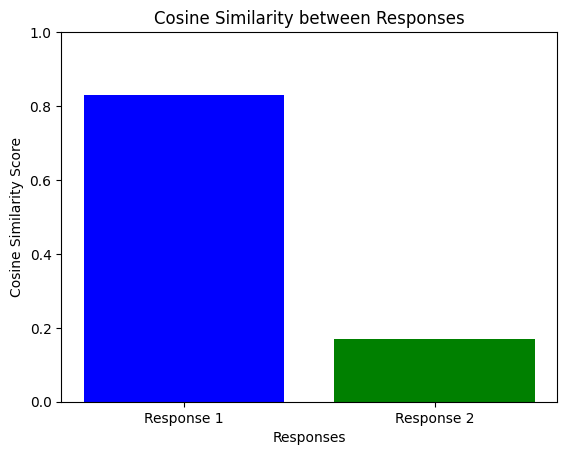

In [21]:
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics.pairwise import cosine_similarity

def get_embedding(text, model_name='stanford-crfm/BioMedLM'):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    
    # Configurer le token de padding si non existant
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token  # Utilise EOS comme PAD
    
    model = AutoModel.from_pretrained(model_name)

    inputs = tokenizer(text, return_tensors='pt', padding=True, truncation=True, max_length=512)

    with torch.no_grad():
        outputs = model(**inputs)

    embeddings = outputs.last_hidden_state.mean(1)
    return embeddings.numpy()

def compare_responses(response1, response2, model_name='stanford-crfm/BioMedLM'):
    emb1 = get_embedding(response1, model_name)
    emb2 = get_embedding(response2, model_name)
    similarity = cosine_similarity(emb1, emb2)
    return similarity[0][0]

# Example usage:
result1 = {'answer': "The patient shows symptoms of influenza."}
result2 = {'answer': "The individual exhibits signs of the flu."}

similarity_score = compare_responses(result1['answer'], result2['answer'])
print("Cosine similarity score:", similarity_score)

# Plotting
labels = ['Response 1', 'Response 2']
scores = [similarity_score, 1 - similarity_score]

plt.bar(labels, scores, color=['blue', 'green'])
plt.title('Cosine Similarity between Responses')
plt.xlabel('Responses')
plt.ylabel('Cosine Similarity Score')
plt.ylim(0, 1)
plt.show()

Cosine similarity score: 0.84970057


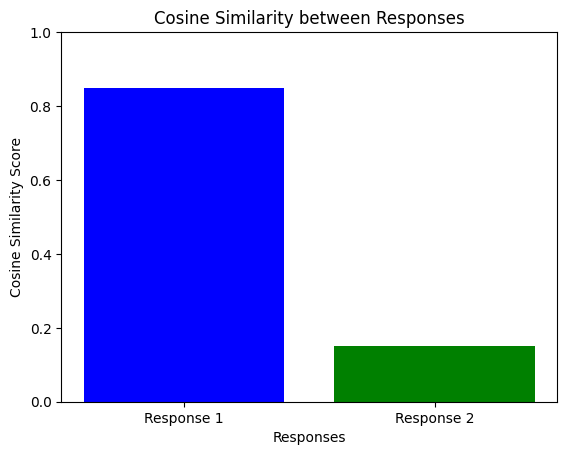

In [22]:
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics.pairwise import cosine_similarity

def get_embedding(text, model_name='microsoft/biogpt'):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    
    # Configurer le token de padding si non existant
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token  # Utilise EOS comme PAD
    
    model = AutoModel.from_pretrained(model_name)

    inputs = tokenizer(text, return_tensors='pt', padding=True, truncation=True, max_length=512)

    with torch.no_grad():
        outputs = model(**inputs)

    embeddings = outputs.last_hidden_state.mean(1)
    return embeddings.numpy()

def compare_responses(response1, response2, model_name='microsoft/biogpt'):
    emb1 = get_embedding(response1, model_name)
    emb2 = get_embedding(response2, model_name)
    similarity = cosine_similarity(emb1, emb2)
    return similarity[0][0]

# Example usage:
result1 = {'answer': "The patient shows symptoms of influenza."}
result2 = {'answer': "The individual exhibits signs of the flu."}

similarity_score = compare_responses(result1['answer'], result2['answer'])
print("Cosine similarity score:", similarity_score)

# Plotting
labels = ['Response 1', 'Response 2']
scores = [similarity_score, 1 - similarity_score]

plt.bar(labels, scores, color=['blue', 'green'])
plt.title('Cosine Similarity between Responses')
plt.xlabel('Responses')
plt.ylabel('Cosine Similarity Score')
plt.ylim(0, 1)
plt.show()

In [23]:
model.save_pretrained("microsoft/biogpt")
tokenizer.save_pretrained("microsoft/biogpt")


('microsoft/biogpt/tokenizer_config.json',
 'microsoft/biogpt/special_tokens_map.json',
 'microsoft/biogpt/tokenizer.model',
 'microsoft/biogpt/added_tokens.json',
 'microsoft/biogpt/tokenizer.json')

In [24]:
model.save_pretrained("stanford-crfm/BioMedLM")
tokenizer.save_pretrained("stanford-crfm/BioMedLM")


('stanford-crfm/BioMedLM/tokenizer_config.json',
 'stanford-crfm/BioMedLM/special_tokens_map.json',
 'stanford-crfm/BioMedLM/tokenizer.model',
 'stanford-crfm/BioMedLM/added_tokens.json',
 'stanford-crfm/BioMedLM/tokenizer.json')

In [25]:
import evaluate

# ROUGE
rouge = evaluate.load("rouge")
rouge_result = rouge.compute(
    predictions=["The heart pumps blood."],
    references=["The heart is responsible for pumping blood."]
)
print("ROUGE:", rouge_result)

# BLEU
bleu = evaluate.load("bleu")
bleu_result = bleu.compute(
    predictions=["The heart pumps blood."],
    references=[["The heart is responsible for pumping blood."]]
)
print("BLEU:", bleu_result)

# BERTScore
from bert_score import score
P, R, F1 = score(
    ["The heart pumps blood."],
    ["The heart is responsible for pumping blood."],
    lang="en", verbose=True
)
print("BERTScore F1:", F1.mean().item())


ROUGE: {'rouge1': 0.5454545454545454, 'rouge2': 0.2222222222222222, 'rougeL': 0.5454545454545454, 'rougeLsum': 0.5454545454545454}


BLEU: {'bleu': 0.0, 'precisions': [0.8, 0.5, 0.0, 0.0], 'brevity_penalty': 0.5488116360940264, 'length_ratio': 0.625, 'translation_length': 5, 'reference_length': 8}


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

...

calculating scores...
computing bert embedding.


  0%|          | 0/1 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/1 [00:00<?, ?it/s]

done in 0.41 seconds, 2.46 sentences/sec
BERTScore F1: 0.9501078724861145


In [26]:
import gradio as gr
from langchain.chains import ConversationalRetrievalChain

def chatbot_response(user_input, max_new_tokens, temperature, context_length):
    # Update the pipeline configuration with user inputs
    pipe.model.config.max_new_tokens = int(max_new_tokens)
    pipe.model.config.temperature = float(temperature)
    pipe.model.config.context_length = int(context_length)

    # Create a conversational retrieval chain with the updated model
    chain = ConversationalRetrievalChain.from_llm(llm, vectorstore.as_retriever(), return_source_documents=True)
    
    # Create a new chat history list, but only return the last answer
    chat_history = []
    
    # Get the result from the chain
    result = chain({"question": user_input, "chat_history": chat_history})
    
    # Return only the last answer
    return f"<div style='max-height: 400px; overflow-y: auto;'>{result['answer']}</div>"

# Setting the Gradio interface
interface = gr.Interface(
    fn=chatbot_response,
    inputs=[
        gr.Textbox(lines=2, placeholder="Type your question here...", label="Your Question", interactive=True),
        gr.Slider(label="Max New Tokens", minimum=1, maximum=2000, value=150, step=1, interactive=True),
        gr.Slider(label="Temperature", minimum=0.1, maximum=1.0, value=0.7, step=0.01, interactive=True),
        gr.Slider(label="Context Length", minimum=100, maximum=4000, value=2000, step=1, interactive=True)
    ],
    outputs=gr.HTML(label="Chatbot Response"),
    title="🩺 MEDICAL Chatbot",
    description="""
    <div style='text-align: center;'>
        <img src='https://cdn.dribbble.com/users/29678/screenshots/2407580/media/34ee4b818fd4ddb3a616c91ccf4d9cfc.png' alt='Medical Bot' width='100'>
        <p>Check the responses from the Medical Llama 3-8B model!</p>
    </div>
    """
)

# Running the interface
interface.launch(share=True)

* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://5c90f447e6bf7b54a6.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
